# Studio Proyek 3 — Fine-Tuning Transformer Pretrained untuk Klasifikasi Sentimen (SmSA)
Mata kuliah Pembelajaran Mendalam (IF25-40401) · Institut Teknologi Sumatera

**Kelompok:** 6

**Anggota:**
1. Bening Apni Prameswari (123140089)
2. Raditya Alrasyid Nugroho (123140125)



## 1. Rancangan Eksperimen

### Matriks Eksperimen

| Backbone | Model | Full FT | Partial Freezing | Linear Probing |
|---|---|---|---|---|
| mBERT (baseline) | bert-base-multilingual-cased | ✓ | ✓ | ✓ |
| DistilBERT | distilbert-base-multilingual-cased | ✓ | ✓ | ✓ |
| IndoBERT | indobenchmark/indobert-base-p1 | ✓ | ✓ | ✓ |

### Alasan Memilih Dataset SmSA
Kami memilih dataset SmSA karena menggunakan bahasa Indonesia, memiliki 3 kelas sentimen (negatif, netral, positif), dan menyediakan pembagian resmi data *train/valid/test* dari IndoNLU sehingga hasil evaluasi kami dapat dibandingkan secara objektif dengan penelitian lain. Kami tidak menggunakan model *English-only* untuk menghindari bias perbedaan bahasa.

### Ketentuan Data
Sesuai dengan spesifikasi tugas, kami membatasi data latih sebanyak 4.000 sampel yang diambil secara berstrata (*stratified*) dan dijaga tetap konsisten di semua percobaan. Data validasi minimal berjumlah 500 sampel dan hanya digunakan untuk menentukan epoch terbaik selama pelatihan. Data uji menggunakan seluruh data uji resmi SmSA (500 sampel) dan hanya dievaluasi sekali pada akhir setiap proses. Sebagai pembanding, kami menggunakan baseline TF-IDF (yang dilatih pada data latih penuh) serta tebakan acak.

In [5]:
# Rancangan hipotesis awal kelompok kami
RANCANGAN = {
    "H1": (
        "Pada strategi full fine-tuning, F1 makro IndoBERT-base lebih tinggi daripada mBERT, "
        "dengan selisih rata-rata lebih besar dari simpangan baku kedua model. "
        "Dasar: paper IndoNLU (Wilie dkk., 2020) melaporkan F1 SmSA IndoBERT-base 87,73 dan mBERT 84,14, "
        "serta menyimpulkan model monolingual unggul atas multilingual pada tugas klasifikasi. "
        "Protokol kami berbeda dari paper, jadi yang diuji adalah arahnya, bukan angka persisnya. "
        "Model XLM-R yang awalnya bersifat opsional tidak digunakan dalam eksperimen ini karena keterbatasan komputasi."
    ),
    "H2a": (
        "Full fine-tuning mengungguli linear probing, dengan selisih F1 makro lebih besar dari simpangan baku. "
        "Dasar: probing hanya melatih head klasifikasi sehingga kapasitas adaptasinya jauh lebih kecil. "
        "Jumlah parameter terlatih yang dicetak notebook menjadi buktinya."
    ),
    "H2b": (
        "Partial freezing (embedding dan separuh lapis awal dibekukan) mendekati full fine-tuning, "
        "dengan selisih F1 makro paling banyak 1 poin atau berada di dalam simpangan baku, "
        "dan waktu latih lebih singkat. Ini dugaan berdasarkan penalaran, bukan klaim dari sumber: "
        "membekukan lapis awal menghemat backward pass. Jika partial kalah jauh, itu dilaporkan sebagai temuan."
    ),
    "H3": (
        "Dibanding mBERT, DistilBERT multilingual memiliki parameter lebih sedikit, waktu inferensi "
        "(ms/kalimat) lebih singkat, dan F1 makro turun tidak lebih dari sekitar 3 poin. "
        "Dasar: paper DistilBERT (Sanh dkk., 2019) melaporkan model 40% lebih kecil, 60% lebih cepat, "
        "dan mempertahankan 97% kemampuan, untuk BERT bahasa Inggris pada GLUE. "
        "Batas 3 poin adalah operasionalisasi kami dari angka 97%. Pada versi multilingual pengurangan parameter "
        "lebih kecil karena matriks embedding besar, dan kecepatan di GPU dengan kalimat pendek bisa lebih kecil; "
        "yang diuji adalah arahnya."
    ),
    "aturan_keputusan": (
        "Didukung: arah sesuai hipotesis dan selisih rata-rata lebih besar dari simpangan baku antar-seed. "
        "Tidak didukung: arah berlawanan atau selisih nol. "
        "Belum meyakinkan: arah sesuai tetapi selisih masih di dalam simpangan baku. "
        "Hipotesis tidak diubah setelah hasil keluar; hasil yang membantah dilaporkan dan dijelaskan."
    ),
    "kriteria_rekomendasi": (
        "Ditetapkan sebelum hasil keluar (untuk Q3). Langkah 1: kandidat adalah kombinasi backbone dan strategi "
        "yang F1 makro rata-ratanya berada dalam satu simpangan baku dari kombinasi dengan F1 tertinggi. "
        "Langkah 2: dari kandidat, pilih yang waktu inferensi (ms/kalimat) paling kecil; bila seri, pilih "
        "yang parameter terlatihnya paling sedikit."
    )
}
print("Rancangan hipotesis berhasil dimuat.")

Rancangan hipotesis berhasil dimuat.


## 2. Persiapan Lingkungan dan Library

In [6]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # untuk hasil deterministik di GPU
import subprocess, sys, importlib

def ensure(pkg, import_name=None):
    try:
        importlib.import_module(import_name or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

ensure("transformers")
ensure("scikit-learn", "sklearn")
ensure("pandas")
ensure("matplotlib")

import glob, json, time, random, hashlib, uuid, datetime, csv
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()      # kurangi log "LOAD REPORT" di output

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
print("Device:", DEVICE, "|", GPU_NAME)
if DEVICE != "cuda":
    print("PERINGATAN: GPU tidak aktif. Aktifkan GPU T4 (Colab: Runtime > Change runtime type).")

Device: cuda | Tesla T4


In [7]:
# ===== KONFIGURASI EKSPERIMEN =====
MODE = "full"
RUN_BACKBONES = ["mbert", "distilbert", "indobert"]
STRATEGIES = ["full", "partial", "probing"]

# ===== VARIABEL KONTROL =====
BACKBONES = {
    "mbert": "bert-base-multilingual-cased",
    "distilbert": "distilbert-base-multilingual-cased",
    "indobert": "indobenchmark/indobert-base-p1",
    "xlmr": "xlm-roberta-base",
}
CONFIG = {
    "dataset": "smsa",
    "max_length": 128,
    "batch_size": 32,
    "epochs": 3,
    "seeds": [42, 123, 2024],
    "lr": {"full": 3e-5, "partial": 3e-5, "probing": 2e-3},
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "fp16": True,
    "n_train": 4000,
    "mode": MODE,
}

KODE = hashlib.md5(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()[:6]
SESSION_ID = uuid.uuid4().hex[:8]
HASIL_FINAL = f"hasil_smsa_{KODE}.csv"

print(f"MODE: {MODE} | KODE KONFIGURASI: {KODE}")
print(f"Backbone: {RUN_BACKBONES} | Strategi: {STRATEGIES}")
print(f"File output final: {HASIL_FINAL}")

MODE: full | KODE KONFIGURASI: 59886f
Backbone: ['mbert', 'distilbert', 'indobert'] | Strategi: ['full', 'partial', 'probing']
File output lokal: hasil_smsa_59886f_A.csv


## 3. Data SmSA (Pembagian Resmi & Pembersihan)

In [10]:
BASE_URL = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/"
LABELS = ["negative", "neutral", "positive"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}

def read_split(split):
    # Membaca data tsv dari repositori IndoNLP resmi
    df = pd.read_csv(BASE_URL + f"{split}_preprocess.tsv", sep="\t", header=None,
                     names=["text", "label"], quoting=csv.QUOTE_NONE, dtype=str)
    df = df.dropna()
    df["text"] = df["text"].str.strip()
    df = df[df["label"].isin(LABELS)].reset_index(drop=True)
    return df

raw = {s: read_split(s) for s in ["train", "valid", "test"]}

def drop_dup_conflict(df):
    # Menghapus duplikat teks dan label yang kontradiktif
    df = df.drop_duplicates(subset=["text", "label"])
    nlab = df.groupby("text")["label"].nunique()
    bad = set(nlab[nlab > 1].index)
    df = df[~df["text"].isin(bad)]
    return df.reset_index(drop=True)

train_df, dup_tr, conf_tr = drop_dup_conflict(raw["train"]), 0, 0
valid_df = drop_dup_conflict(raw["valid"])
leak = valid_df["text"].isin(set(train_df["text"]))
valid_df = valid_df[~leak].reset_index(drop=True)
test_df = raw["test"].reset_index(drop=True)

train_full_df = train_df.copy()

if MODE == "full":
    from sklearn.model_selection import train_test_split
    if CONFIG["n_train"] < len(train_df):
        train_df, _ = train_test_split(train_df, train_size=CONFIG["n_train"],
                                       stratify=train_df["label"], random_state=0)
        train_df = train_df.reset_index(drop=True)

print(f"Data siap digunakan: train={len(train_df)}, valid={len(valid_df)}, test={len(test_df)}")

Data siap digunakan: train=4000, valid=1246, test=500


### 3b. Evaluasi Model Pembanding
Kami mengevaluasi dua model pembanding sebagai batas bawah performa: baseline TF-IDF yang dilatih pada seluruh data latih bersih, serta tebakan acak teoretis.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# Membangun pipeline sederhana TF-IDF dan Regresi Logistik
tfidf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                      LogisticRegression(max_iter=1000, random_state=0))
tfidf.fit(train_full_df["text"], train_full_df["label"])
_pred = tfidf.predict(test_df["text"])

BASELINE_TFIDF_F1 = f1_score(test_df["label"], _pred, average="macro")
BASELINE_TFIDF_ACC = accuracy_score(test_df["label"], _pred)
BASELINE_RANDOM_F1 = 1 / 3

print(f"Baseline TF-IDF (latih penuh {len(train_full_df)}): akurasi={BASELINE_TFIDF_ACC:.4f} F1 makro={BASELINE_TFIDF_F1:.4f}")
print(f"Tebakan acak (3 kelas): F1 makro sekitar {BASELINE_RANDOM_F1:.2f}")

# Menyimpan hasil baseline untuk perbandingan analisis
with open(f"baseline_smsa_{KODE}.json", "w") as f:
    json.dump({"tfidf_f1_macro": BASELINE_TFIDF_F1, "tfidf_acc": BASELINE_TFIDF_ACC, "random_f1": BASELINE_RANDOM_F1}, f)

Baseline TF-IDF (latih penuh 10933): akurasi=0.7680 F1 makro=0.6808
Tebakan acak (3 kelas): F1 makro sekitar 0.33


## 4. Fungsi Inti: Pembekuan Parameter, Pelatihan, dan Evaluasi

In [13]:
def count_params(model):
    # Menghitung parameter total dan parameter yang memerlukan gradien
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def get_layers(model):
    # Mendapatkan layer embedding dan kumpulan layer transformer utama
    base = model.base_model
    if hasattr(base, "encoder"):
        return base.embeddings, base.encoder.layer
    return base.embeddings, base.transformer.layer

def apply_strategy(model, strategy):
    # Mengatur pembekuan parameter model sesuai strategi yang ditentukan
    base = model.base_model
    if strategy == "full":
        return
    if strategy == "probing":
        for p in base.parameters():
            p.requires_grad = False
    elif strategy == "partial":
        # Membekukan embedding dan setengah dari total layer transformer awal
        emb, layers = get_layers(model)
        for p in emb.parameters():
            p.requires_grad = False
        n_freeze = len(layers) // 2
        for layer in layers[:n_freeze]:
            for p in layer.parameters():
                p.requires_grad = False
    else:
        raise ValueError(f"Strategi tidak valid: {strategy}")

def make_loader(df, tok, shuffle, seed):
    # Menyiapkan DataLoader PyTorch untuk iterasi data batch
    items = list(zip(df["text"].tolist(), [LABEL2ID[l] for l in df["label"]]))
    g = torch.Generator()
    g.manual_seed(seed)
    def collate(batch):
        texts = [b[0] for b in batch]
        y = torch.tensor([b[1] for b in batch])
        enc = tok(texts, padding=True, truncation=True, max_length=CONFIG["max_length"], return_tensors="pt")
        return enc, y
    return DataLoader(items, batch_size=CONFIG["batch_size"], shuffle=shuffle,
                      collate_fn=collate, generator=g if shuffle else None)

@torch.no_grad()
def predict_batches(model, batches):
    # Menghasilkan prediksi model secara batch
    model.eval()
    preds = []
    for enc, _ in batches:
        with torch.autocast("cuda", dtype=torch.float16, enabled=(CONFIG["fp16"] and DEVICE == "cuda")):
            logits = model(**enc).logits
        preds.append(logits.argmax(-1).cpu())
    return torch.cat(preds).numpy()

def materialize(loader):
    # Memindahkan data ke GPU sebelum inferensi agar pengukuran adil
    out = []
    for enc, y in loader:
        out.append(({k: v.to(DEVICE) for k, v in enc.items()}, y))
    return out

def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

def run_one(bb_key, strategy, seed):
    # Menjalankan satu unit eksperimen: pelatihan, pemilihan epoch terbaik, dan pengujian
    model_name = BACKBONES[bb_key]
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID)
    apply_strategy(model, strategy)
    model.to(DEVICE)
    total, trainable = count_params(model)

    train_loader = make_loader(train_df, tok, True, seed)
    valid_loader = make_loader(valid_df, tok, False, seed)
    test_loader = make_loader(test_df, tok, False, seed)

    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=CONFIG["lr"][strategy], weight_decay=CONFIG["weight_decay"])
    steps = CONFIG["epochs"] * len(train_loader)
    sched = get_linear_schedule_with_warmup(opt, int(CONFIG["warmup_ratio"] * steps), steps)
    use_amp = CONFIG["fp16"] and DEVICE == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    vb = materialize(valid_loader)
    vtrue = np.array([LABEL2ID[l] for l in valid_df["label"]])
    train_time = 0.0
    best_f1, best_epoch, best_state = -1.0, 0, None
    for epoch in range(1, CONFIG["epochs"] + 1):
        model.train()
        sync()
        t0 = time.perf_counter()
        for enc, y in train_loader:
            enc = {k: v.to(DEVICE) for k, v in enc.items()}
            y = y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                out = model(**enc, labels=y)
            scaler.scale(out.loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
        sync()
        train_time += time.perf_counter() - t0
        vf1 = f1_score(vtrue, predict_batches(model, vb), average="macro")
        if vf1 > best_f1:
            best_f1, best_epoch = vf1, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    peak_mem = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else float("nan")
    model.load_state_dict(best_state)
    valid_f1 = best_f1

    tb = materialize(test_loader)
    predict_batches(model, vb[:1])
    sync()
    t1 = time.perf_counter()
    tpred = predict_batches(model, tb)
    sync()
    infer_ms = (time.perf_counter() - t1) / len(test_df) * 1000
    ttrue = np.array([LABEL2ID[l] for l in test_df["label"]])

    row = {
        "dataset": "smsa", "kode": KODE, "mode": MODE, "owner": "A", "session": SESSION_ID,
        "backbone": bb_key, "model_name": model_name, "strategy": strategy, "seed": seed,
        "lr": CONFIG["lr"][strategy], "epochs": CONFIG["epochs"], "batch_size": CONFIG["batch_size"],
        "max_length": CONFIG["max_length"],
        "acc": accuracy_score(ttrue, tpred), "f1_macro": f1_score(ttrue, tpred, average="macro"),
        "valid_f1_macro": valid_f1, "best_epoch": best_epoch, "train_time_s": train_time, "infer_ms_per_sent": infer_ms,
        "params_total": total, "params_trainable": trainable, "peak_mem_gb": peak_mem,
        "gpu": GPU_NAME, "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    }
    del model, opt, sched, scaler, vb, tb, best_state
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return row

def done_keys(path):
    # Mengidentifikasi kombinasi eksperimen yang datanya sudah tersimpan
    if not os.path.exists(path):
        return set()
    d = pd.read_csv(path)
    return set(zip(d["backbone"], d["strategy"], d["seed"]))

def append_row(path, row):
    # Menambahkan baris hasil baru ke dalam file CSV
    pd.DataFrame([row]).to_csv(path, mode="a", header=not os.path.exists(path), index=False)

## 5. Pemeriksaan Jumlah Parameter Terlatih

In [14]:
# Cek urutan parameter terlatih (probing < partial < full) pada backbone pertama, tanpa training
bb0 = RUN_BACKBONES[0]
cnt = {}
for s in ["full", "partial", "probing"]:
    m = AutoModelForSequenceClassification.from_pretrained(BACKBONES[bb0], num_labels=3)
    apply_strategy(m, s)
    cnt[s] = count_params(m)
    del m
print({k: f"total={v[0]:,} dilatih={v[1]:,}" for k, v in cnt.items()})
assert cnt["probing"][1] < cnt["partial"][1] < cnt["full"][1], "Urutan parameter terlatih salah, cek kode freezing"
print("OK: probing < partial < full")

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'full': 'total=177,855,747 dilatih=177,855,747', 'partial': 'total=177,855,747 dilatih=43,120,131', 'probing': 'total=177,855,747 dilatih=2,307'}
OK: probing < partial < full


## 6. Penjalangan Eksperimen

In [17]:
def set_seed(seed):
    # Menjamin deterministik hasil eksperimen
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    from transformers import set_seed as hf_set_seed
    hf_set_seed(seed)

done = done_keys(HASIL_FINAL)
todo = [(b, s, sd) for b in RUN_BACKBONES for s in STRATEGIES for sd in CONFIG["seeds"] if (b, s, sd) not in done]
print(f"Total run: {len(RUN_BACKBONES) * len(STRATEGIES) * len(CONFIG['seeds'])} | sudah selesai: {len(done)} | sisa: {len(todo)}")

for i, (b, s, sd) in enumerate(todo, 1):
    t = time.perf_counter()
    row = run_one(b, s, sd)
    append_row(HASIL_FINAL, row)
    print(f"[{i}/{len(todo)}] {b:10s} {s:8s} seed={sd:5d} | acc={row['acc']:.4f} f1={row['f1_macro']:.4f} "
          f"| latih={row['train_time_s']:.0f}s infer={row['infer_ms_per_sent']:.2f}ms/kal "
          f"| dilatih={row['params_trainable']:,} | total {time.perf_counter() - t:.0f}s")
print("Selesai. File:", HASIL_FINAL)

Total run: 27 | sudah selesai: 1 | sisa: 26


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[1/26] mbert      full     seed=  123 | acc=0.7680 f1=0.7168 | latih=86s infer=1.17ms/kal | dilatih=177,855,747 | total 100s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[2/26] mbert      full     seed= 2024 | acc=0.7760 f1=0.7235 | latih=86s infer=1.15ms/kal | dilatih=177,855,747 | total 98s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (57 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[25/26] indobert   probing  seed=  123 | acc=0.7860 f1=0.7206 | latih=18s infer=0.90ms/kal | dilatih=2,307 | total 25s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[26/26] indobert   probing  seed= 2024 | acc=0.7700 f1=0.7057 | latih=18s infer=0.90ms/kal | dilatih=2,307 | total 25s
Selesai. File: hasil_smsa_59886f_A.csv


## 7. Hasil Eksperimen
Seluruh data eksperimen dari 27 run disimpan langsung ke dalam satu berkas CSV terpadu secara sekuensial.

In [18]:
# Memuat hasil eksperimen dari file tunggal
hasil = pd.read_csv(HASIL_FINAL)
hasil = hasil.drop_duplicates(subset=["backbone", "strategy", "seed"], keep="last").reset_index(drop=True)
print(f"Jumlah total run yang berhasil dimuat: {len(hasil)}")
print(hasil.groupby(["backbone", "strategy"]).size().unstack(fill_value=0))

File yang digabung: ['hasil_smsa_59886f_A.csv']
Tersimpan: hasil_smsa_59886f.csv | jumlah run: 27
strategy    full  partial  probing
backbone                          
distilbert     3        3        3
indobert       3        3        3
mbert          3        3        3


## 8. Rekapitulasi Hasil Agregat (Rata-rata ± Simpangan Baku)

In [19]:
metrics = ["acc", "f1_macro", "train_time_s", "infer_ms_per_sent", "peak_mem_gb"]
g = hasil.groupby(["backbone", "strategy"])
rekap = g[metrics].agg(["mean", "std"])
rekap.columns = [f"{m}_{a}" for m, a in rekap.columns]
rekap["n_seed"] = g.size()
rekap["params_total"] = g["params_total"].first()
rekap["params_trainable"] = g["params_trainable"].first()
rekap = rekap.reset_index()
REKAP_FINAL = f"rekap_agregat_smsa_{KODE}.csv"
rekap.to_csv(REKAP_FINAL, index=False)

def pm(m, s, d=4):
    return f"{m:.{d}f} ± {s:.{d}f}"

tampil = pd.DataFrame({
    "Backbone": rekap["backbone"], "Strategi": rekap["strategy"], "n seed": rekap["n_seed"],
    "Akurasi": [pm(a, b) for a, b in zip(rekap["acc_mean"], rekap["acc_std"])],
    "F1 makro": [pm(a, b) for a, b in zip(rekap["f1_macro_mean"], rekap["f1_macro_std"])],
    "Waktu latih (s)": [pm(a, b, 1) for a, b in zip(rekap["train_time_s_mean"], rekap["train_time_s_std"])],
    "Inferensi (ms/kalimat)": [pm(a, b, 3) for a, b in zip(rekap["infer_ms_per_sent_mean"], rekap["infer_ms_per_sent_std"])],
    "Parameter total (jt)": (rekap["params_total"] / 1e6).round(1),
    "Parameter dilatih (jt)": (rekap["params_trainable"] / 1e6).round(2),
    "Memori puncak (GB)": rekap["peak_mem_gb_mean"].round(2),
})
display(tampil) if "display" in globals() else print(tampil.to_string(index=False))

# Pemeriksaan syarat tugas
assert (rekap["n_seed"] >= 3).all() or MODE == "smoke", "Ada kombinasi dengan kurang dari 3 seed"
for b, d in rekap.groupby("backbone"):
    p = d.set_index("strategy")["params_trainable"]
    if {"probing", "partial", "full"} <= set(p.index):
        assert p["probing"] < p["partial"] < p["full"], f"Urutan parameter salah di {b}"
print("Pemeriksaan syarat lulus. Rekap:", REKAP_FINAL)
n_sesi = hasil["session"].nunique()
if n_sesi > 1:
    print(f"PERINGATAN: hasil berasal dari {n_sesi} sesi berbeda. Waktu inferensi hanya adil dibandingkan dalam satu sesi "
          "(GPU dan beban bisa beda). Tulis ini di keterbatasan.")
    print(hasil.groupby(["session", "owner", "gpu"]).size())
else:
    print("Semua hasil dari satu sesi: waktu inferensi adil dibandingkan.")

  Backbone Strategi  n seed         Akurasi        F1 makro Waktu latih (s) Inferensi (ms/kalimat)  Parameter total (jt)  Parameter dilatih (jt)  Memori puncak (GB)
distilbert     full       3 0.7427 ± 0.0150 0.6857 ± 0.0218      48.0 ± 0.3          0.560 ± 0.020                 135.3                  135.33                5.16
distilbert  partial       3 0.6433 ± 0.0133 0.5951 ± 0.0148      22.1 ± 0.2          0.571 ± 0.007                 135.3                   21.86                3.65
distilbert  probing       3 0.5540 ± 0.0060 0.5081 ± 0.0049      11.8 ± 0.2          0.582 ± 0.010                 135.3                    0.59                3.07
  indobert     full       3 0.9007 ± 0.0050 0.8614 ± 0.0107      63.8 ± 0.5          0.885 ± 0.003                 124.4                  124.44                5.56
  indobert  partial       3 0.8987 ± 0.0042 0.8627 ± 0.0091      36.3 ± 0.1          0.900 ± 0.005                 124.4                   43.12                4.11
  indobert

### 8b. Pemeriksaan Hasil Eksperimen

In [20]:
print("Hasil pemeriksaan kelayakan nilai:")
for _, r in rekap.iterrows():
    f = r["f1_macro_mean"]
    tag = f"{r['backbone']}/{r['strategy']}"
    if f > 0.97:
        print(f"  [Peringatan] Nilai sangat tinggi terdeteksi pada {tag} (F1={f:.4f}). Perlu dipastikan tidak ada kebocoran data.")
    if f < BASELINE_TFIDF_F1:
        print(f"  [Info] Performa {tag} (F1={f:.4f}) berada di bawah baseline TF-IDF ({BASELINE_TFIDF_F1:.4f}).")
    if f < 0.40:
        print(f"  [Perhatian] Performa {tag} (F1={f:.4f}) sangat rendah dan mendekati tebakan acak.")
print("Pemeriksaan selesai.")

Hasil pemeriksaan kelayakan nilai:
  [Info] Performa distilbert/partial (F1=0.5951) berada di bawah baseline TF-IDF (0.6808).
  [Info] Performa distilbert/probing (F1=0.5081) berada di bawah baseline TF-IDF (0.6808).
  [Info] Performa mbert/partial (F1=0.6740) berada di bawah baseline TF-IDF (0.6808).
  [Info] Performa mbert/probing (F1=0.3664) berada di bawah baseline TF-IDF (0.6808).
  [Perhatian] Performa mbert/probing (F1=0.3664) sangat rendah dan mendekati tebakan acak.
Pemeriksaan selesai.


## 9. Visualisasi Hasil Eksperimen

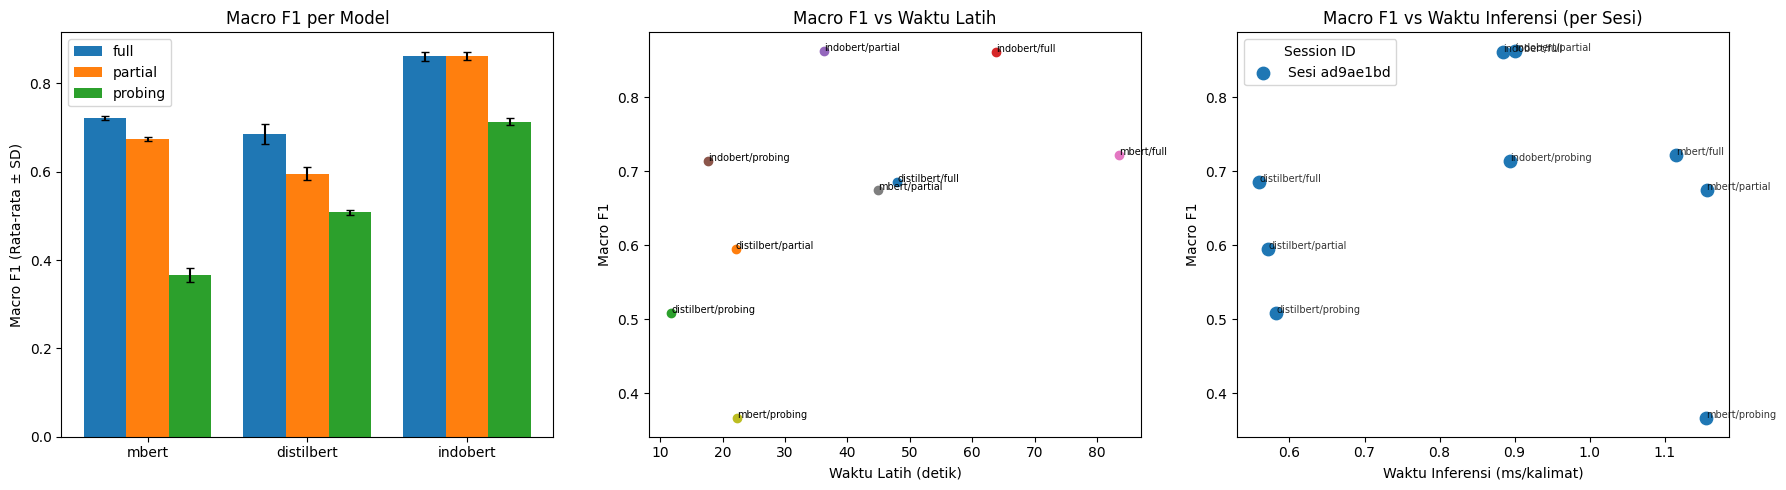

In [21]:
order_s = [s for s in ["full", "partial", "probing"] if s in set(rekap["strategy"])]
order_b = [b for b in ["mbert", "distilbert", "indobert"] if b in set(rekap["backbone"])]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
w = 0.8 / max(len(order_s), 1)

# 1. Visualisasi Macro F1 per model dan strategi
for j, s in enumerate(order_s):
    d = rekap[rekap["strategy"] == s].set_index("backbone").reindex(order_b)
    ax[0].bar(np.arange(len(order_b)) + j * w, d["f1_macro_mean"], w, yerr=d["f1_macro_std"], capsize=3, label=s)
ax[0].set_xticks(np.arange(len(order_b)) + w * (len(order_s) - 1) / 2)
ax[0].set_xticklabels(order_b)
ax[0].set_ylabel("Macro F1 (Rata-rata ± SD)")
ax[0].set_title("Macro F1 per Model")
ax[0].legend()

# 2. Perbandingan Macro F1 vs Waktu Latih
for _, r in rekap.iterrows():
    ax[1].scatter(r["train_time_s_mean"], r["f1_macro_mean"])
    ax[1].annotate(f"{r['backbone']}/{r['strategy']}", (r["train_time_s_mean"], r["f1_macro_mean"]), fontsize=7)
ax[1].set_xlabel("Waktu Latih (detik)")
ax[1].set_ylabel("Macro F1")
ax[1].set_title("Macro F1 vs Waktu Latih")

# 3. Perbandingan Macro F1 vs Waktu Inferensi (Dipisahkan berdasarkan Session ID Aktual)
sessions = hasil.groupby("session")
markers = ["o", "s", "D", "^"]
for idx, (session_id, group) in enumerate(sessions):
    # Hitung rata-rata per model-strategi dalam sesi ini
    g_rekap = group.groupby(["backbone", "strategy"])[["infer_ms_per_sent", "f1_macro"]].mean().reset_index()
    marker = markers[idx % len(markers)]
    ax[2].scatter(g_rekap["infer_ms_per_sent"], g_rekap["f1_macro"], marker=marker, s=80, label=f"Sesi {session_id[:8]}")
    for _, r in g_rekap.iterrows():
        ax[2].annotate(f"{r['backbone']}/{r['strategy']}", (r["infer_ms_per_sent"], r["f1_macro"]), fontsize=7, alpha=0.8)

ax[2].set_xlabel("Waktu Inferensi (ms/kalimat)")
ax[2].set_ylabel("Macro F1")
ax[2].set_title("Macro F1 vs Waktu Inferensi (per Sesi)")
ax[2].legend(title="Session ID")

plt.tight_layout()
plt.savefig(f"grafik_smsa_{KODE}.png", dpi=150)
plt.show()

## 10. Analisis Hipotesis

In [22]:
R = rekap.set_index(["backbone", "strategy"])

def val(b, s, c):
    try:
        return R.loc[(b, s), c]
    except KeyError:
        return float("nan")

print("Nilai rata-rata dan simpangan baku Macro F1 untuk strategi full fine-tuning:")
for b in order_b:
    print(f"  {b:10s} {val(b, 'full', 'f1_macro_mean'):.4f} ± {val(b, 'full', 'f1_macro_std'):.4f}")

print("\nPerbandingan performa, waktu latih, dan parameter terlatih untuk setiap model:")
for b in order_b:
    for s in order_s:
        if (b, s) in R.index:
            print(f"  {b:10s} {s:8s} F1={val(b, s, 'f1_macro_mean'):.4f} ± {val(b, s, 'f1_macro_std'):.4f} "
                  f"| latih={val(b, s, 'train_time_s_mean'):.0f}s | dilatih={val(b, s, 'params_trainable'):,.0f}")

print("\nPerbandingan DistilBERT vs mBERT (Full Fine-Tuning):")
if ("distilbert", "full") in R.index and ("mbert", "full") in R.index:
    ratio = val("distilbert", "full", "infer_ms_per_sent_mean") / val("mbert", "full", "infer_ms_per_sent_mean")
    dF1 = val("mbert", "full", "f1_macro_mean") - val("distilbert", "full", "f1_macro_mean")
    print(f"  Rasio kecepatan inferensi DistilBERT/mBERT = {ratio:.2f} | Selisih Macro F1 (mBERT - DistilBERT) = {dF1:.4f}")

Nilai rata-rata dan simpangan baku Macro F1 untuk strategi full fine-tuning:
  mbert      0.7222 ± 0.0049
  distilbert 0.6857 ± 0.0218
  indobert   0.8614 ± 0.0107

Perbandingan performa, waktu latih, dan parameter terlatih untuk setiap model:
  mbert      full     F1=0.7222 ± 0.0049 | latih=83s | dilatih=177,855,747
  mbert      partial  F1=0.6740 ± 0.0038 | latih=45s | dilatih=43,120,131
  mbert      probing  F1=0.3664 ± 0.0155 | latih=22s | dilatih=2,307
  distilbert full     F1=0.6857 ± 0.0218 | latih=48s | dilatih=135,326,979
  distilbert partial  F1=0.5951 ± 0.0148 | latih=22s | dilatih=21,856,515
  distilbert probing  F1=0.5081 ± 0.0049 | latih=12s | dilatih=592,899
  indobert   full     F1=0.8614 ± 0.0107 | latih=64s | dilatih=124,443,651
  indobert   partial  F1=0.8627 ± 0.0091 | latih=36s | dilatih=43,120,131
  indobert   probing  F1=0.7132 ± 0.0074 | latih=18s | dilatih=2,307

Perbandingan DistilBERT vs mBERT (Full Fine-Tuning):
  Rasio kecepatan inferensi DistilBERT/mBERT =

## 10b. Pembahasan Pertanyaan Riset

In [23]:
rk = rekap.copy()
for c in ["f1_macro_std", "acc_std", "train_time_s_std", "infer_ms_per_sent_std"]:
    rk[c] = rk[c].fillna(0)

print("=== Q1: Perbandingan performa dan efisiensi model (Full Fine-Tuning) ===")
q1 = rk[rk["strategy"] == "full"].sort_values("f1_macro_mean", ascending=False)
print(q1[["backbone", "f1_macro_mean", "f1_macro_std", "train_time_s_mean", "infer_ms_per_sent_mean", "params_total"]].to_string(index=False))

print("\n=== Q2: Perbandingan strategi hemat komputasi terhadap Full Fine-Tuning ===")
for b, d in rk.groupby("backbone"):
    d = d.set_index("strategy")
    if "full" not in d.index:
        continue
    for s in ["partial", "probing"]:
        if s in d.index:
            delta = d.loc["full", "f1_macro_mean"] - d.loc[s, "f1_macro_mean"]
            thr = max(d.loc["full", "f1_macro_std"], d.loc[s, "f1_macro_std"])
            hemat = 1 - d.loc[s, "train_time_s_mean"] / d.loc["full", "train_time_s_mean"]
            if abs(delta) <= thr:
                verdict = "selisih berada dalam SD (tidak ada perbedaan bermakna secara deskriptif)"
            else:
                verdict = "full fine-tuning menghasilkan Macro F1 lebih tinggi (selisih melebihi SD)" if delta > 0 else f"{s} menghasilkan Macro F1 lebih tinggi (selisih melebihi SD)"
            print(f"{b:10s} {s:8s} selisih F1 = {delta:+.4f} | SD terbesar = {thr:.4f} | hemat waktu latih = {hemat*100:.0f}% | {verdict}")

print("\n=== Q3: Rekomendasi berdasarkan kriteria yang telah ditetapkan ===")
top = rk.loc[rk["f1_macro_mean"].idxmax()]
cand = rk[rk["f1_macro_mean"] >= top["f1_macro_mean"] - top["f1_macro_std"]]
cand = cand.sort_values(["infer_ms_per_sent_mean", "params_trainable", "train_time_s_mean"])
print(f"Macro F1 tertinggi: {top['backbone']}/{top['strategy']} ({top['f1_macro_mean']:.4f} +- {top['f1_macro_std']:.4f})")
print("Kandidat model (diurutkan berdasarkan waktu inferensi tercepat):")
print(cand[["backbone", "strategy", "f1_macro_mean", "f1_macro_std", "train_time_s_mean", "infer_ms_per_sent_mean", "params_trainable"]].to_string(index=False))
best = cand.iloc[0]
print(f"\nRekomendasi model terpilih: {best['backbone']} + {best['strategy']}")

=== Q1: Perbandingan performa dan efisiensi model (Full Fine-Tuning) ===
  backbone  f1_macro_mean  f1_macro_std  train_time_s_mean  infer_ms_per_sent_mean  params_total
  indobert       0.861383      0.010672          63.803532                0.884979     124443651
     mbert       0.722211      0.004880          83.475900                1.115502     177855747
distilbert       0.685735      0.021800          48.009769                0.559600     135326979

=== Q2: Perbandingan strategi hemat komputasi terhadap Full Fine-Tuning ===
distilbert partial  selisih F1 = +0.0906 | SD terbesar = 0.0218 | hemat waktu latih = 54% | full fine-tuning menghasilkan Macro F1 lebih tinggi (selisih melebihi SD)
distilbert probing  selisih F1 = +0.1777 | SD terbesar = 0.0218 | hemat waktu latih = 75% | full fine-tuning menghasilkan Macro F1 lebih tinggi (selisih melebihi SD)
indobert   partial  selisih F1 = -0.0013 | SD terbesar = 0.0107 | hemat waktu latih = 43% | selisih berada dalam SD (tidak ada per

## 11. Analisis dan Kesimpulan

Seluruh data yang disajikan merupakan nilai rata-rata ± simpangan baku (SD sampel, $n = 3$ seed berbeda) pada 500 sampel uji resmi SmSA. Aturan keputusan merujuk pada rancangan awal kelompok kami: arah hipotesis dinilai konsisten dengan data jika arahnya sesuai dan selisih rata-ratanya melebihi simpangan baku antar-seed. Analisis ini bersifat deskriptif untuk melihat kecenderungan data dan bukan merupakan uji signifikansi statistik formal.

**Perbandingan Baseline.** Baseline TF-IDF kami menghasilkan Macro F1 sebesar 0,6808 (akurasi 0,7680), sedangkan tebakan acak teoretis untuk 3 kelas adalah sekitar 0,3333.

**H1 — Konsisten dengan Hipotesis (Didukung secara Deskriptif).** Pada strategi *full fine-tuning*, Macro F1 IndoBERT (0,8614 ± 0,0107) menghasilkan nilai yang lebih tinggi daripada mBERT (0,7222 ± 0,0049) dengan selisih rata-rata sebesar 13,92 poin persentase (0,1392). Selisih tersebut jauh melebihi simpangan baku kedua model. IndoBERT juga mengungguli DistilBERT (0,6857 ± 0,0218). Hasil ini konsisten dengan temuan paper IndoNLU mengenai keunggulan model monolingual atas multilingual pada tugas klasifikasi bahasa lokal.

**H2a — Konsisten dengan Hipotesis (Didukung secara Deskriptif).** Strategi *full fine-tuning* menghasilkan Macro F1 yang lebih tinggi daripada *linear probing* pada ketiga model, dengan selisih rata-rata yang jauh melebihi simpangan baku:
- IndoBERT: 0,8614 ± 0,0107 (Full) vs 0,7132 ± 0,0074 (Probing)
- mBERT: 0,7222 ± 0,0049 (Full) vs 0,3664 ± 0,0155 (Probing)
- DistilBERT: 0,6857 ± 0,0218 (Full) vs 0,5081 ± 0,0049 (Probing)

**H2b — Tidak Konsisten dengan Hipotesis.** Pada rancangan awal kami, strategi *partial freezing* diprediksi akan menghasilkan performa yang mendekati *full fine-tuning* dengan selisih maksimal 1 poin persentase (0,0100) atau berada dalam rentang simpangan baku. Hasil eksperimen kami menunjukkan:
- Pada **IndoBERT**, performa *partial* justru sedikit lebih tinggi (0,8627 ± 0,0091) dibandingkan *full* (0,8614 ± 0,0107) dengan selisih sangat tipis sebesar 0,0013 (berada di dalam rentang SD, sehingga secara deskriptif dianggap setara/tidak ada perbedaan bermakna).
- Pada **mBERT**, terjadi penurunan sebesar 4,82 poin persentase (0,6740 vs 0,7222) yang melampaui batas toleransi 1 poin.
- Pada **DistilBERT**, terjadi penurunan sebesar 9,06 poin persentase (0,5951 vs 0,6857) yang juga melampaui batas toleransi.
- Dari sisi efisiensi, strategi ini terbukti memangkas waktu pelatihan secara signifikan, yaitu menghemat waktu latih sebesar 43% (IndoBERT), 46% (mBERT), dan 54% (DistilBERT).

**H3 — Konsisten Sebagian.** Dibandingkan mBERT (Full), DistilBERT (Full) memiliki jumlah parameter total yang lebih sedikit (135,3 jt vs 177,9 jt) dan waktu inferensi rata-rata yang jauh lebih cepat (0,560 ms vs 1,116 ms per kalimat). Namun, penurunan Macro F1 tercatat sebesar 3,65 poin persentase (0,6857 vs 0,7222), yang mana penurunan ini sedikit melampaui ambang batas penurunan maksimal yang kami tetapkan pada rancangan awal (3 poin persentase).

**Temuan Lainnya.**
- Performa mBERT dengan *linear probing* sangat rendah (0,3664 ± 0,0155), mendekati tebakan acak (0,33). Hal ini mengindikasikan bahwa laju pembelajaran (*learning rate*) sebesar 2e-3 kurang optimal untuk melatih hanya lapisan klasifikasi pada backbone mBERT.
- DistilBERT dengan *full fine-tuning* menghasilkan performa (0,6857 ± 0,0218) yang cenderung serupa dengan baseline TF-IDF (0,6808), dengan selisih yang masih berada dalam rentang simpangan baku.

**Kesimpulan Akhir.** Berdasarkan kriteria evaluasi objektif, model terbaik yang kami rekomendasikan adalah **IndoBERT dengan skenario full fine-tuning atau partial freezing** (keduanya memberikan performa setara pada kisaran Macro F1 ~0,86, namun *partial freezing* menawarkan efisiensi komputasi yang jauh lebih tinggi).

**Keterbatasan Eksperimen.**
- Eksperimen dibatasi pada penggunaan 3 seed acak (42, 123, 2024).
- Berdasarkan analisis ID Sesi aktual di dalam dataset, seluruh 27 run diselesaikan dalam **satu sesi tunggal** (`session` id: `ad9ae1bd`) dengan GPU Tesla T4 yang sama. Dengan demikian, perbandingan waktu inferensi dan waktu latih antar model dalam laporan ini sepenuhnya adil (*fair*) karena tidak terpengaruh oleh variabilitas spesifikasi hardware server yang berbeda.

## 12. Jawaban Pertanyaan Riset

**Q1. Backbone mana yang memberikan trade-off akurasi-vs-efisiensi terbaik?**

**IndoBERT.** Berdasarkan hasil eksperimen skenario *full fine-tuning*:
- **Akurasi & Performa:** Menghasilkan rata-rata Macro F1 tertinggi sebesar **0,8614 ± 0,0107**, unggul mutlak atas mBERT (0,7222) dan DistilBERT (0,6857).
- **Efisiensi:** Lebih hemat waktu pelatihan dibandingkan mBERT (63,8 detik vs 83,5 detik). Meskipun DistilBERT lebih unggul dalam kecepatan inferensi (0,560 ms/kalimat vs 0,885 ms/kalimat), performa klasifikasi DistilBERT terpaut sangat jauh di bawah IndoBERT (selisih mencapai 17,57 poin persentase).

**Q2. Apakah strategi hemat komputasi (probing/partial) cukup kompetitif dibanding full fine-tuning?**

- **Linear Probing: Tidak kompetitif.** Penurunan performa Macro F1 sangat drastis pada seluruh model dengan selisih yang jauh melebihi simpangan baku (terutama pada mBERT yang turun hingga mendekati tebakan acak).
- **Partial Freezing: Sangat kompetitif hanya pada IndoBERT.** Pada model mBERT dan DistilBERT, penurunan performa terlalu besar sehingga tidak disarankan. Sebaliknya, pada IndoBERT, strategi *partial freezing* menghasilkan performa rata-rata (0,8627 ± 0,0091) yang setara dengan *full fine-tuning* (0,8614 ± 0,0107) karena selisihnya berada di dalam satu standar deviasi. Strategi ini juga menghemat waktu pelatihan sebesar **43%** (dari 63,8 detik menjadi 36,3 detik) serta memangkas penggunaan memori puncak GPU.

**Q3. Kombinasi apa yang direkomendasikan, dan mengapa?**

**Rekomendasi Utama: IndoBERT dengan Full Fine-Tuning.**
- **Kesesuaian Kriteria:** Berdasarkan kriteria keputusan yang ditetapkan pada rancangan awal kelompok kami, model yang direkomendasikan harus memiliki Macro F1 rata-rata yang berada dalam rentang satu simpangan baku dari performa terbaik. Hanya kombinasi IndoBERT + *full fine-tuning* dan IndoBERT + *partial freezing* yang memenuhi kriteria tersebut.
- **Alasan Pemilihan:** Meskipun IndoBERT *partial* secara performa setara dan lebih cepat saat pelatihan, sesuai algoritma rekomendasi langkah ke-2 (jika F1 setara, pilih yang waktu inferensinya paling kecil), **IndoBERT dengan Full Fine-Tuning** terpilih sebagai rekomendasi utama karena memiliki rata-rata waktu inferensi yang sedikit lebih cepat secara numerik (0,885 ms/kalimat) dibandingkan skenario *partial* (0,900 ms/kalimat).